In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.svm import LinearSVC
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix
import warnings
warnings.filterwarnings("ignore") #liblinear keeps giving convergence warnings

Problem 1 Breast cancer wisconsin

In [2]:
#linking the dataset , there is no header in this file so header = None
df=pd.read_csv(r"F:\USC_EE\Sem_3\DSCI_552\Hw8\wdbc.data", header=None)

In [3]:
print(df.shape) # number of rows and columns
df.head() #first 5 rows

(569, 32)


,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [4]:
#column 0 is the id , column 1 is the diagnosis and the rest 30 are features
#encoding M as 1 since malignant is the positive class and B as 0
X= df.iloc[:, 2:].values
y= df[1].map({"B": 0, "M": 1 }).values
print("Benign:", (y==0).sum(), "Malignant:", (y==1).sum())

Benign: 357 Malignant: 212


In [5]:
#function to get all the scores in one go so i dont have to write it again for every method
def getscores(ytrue, ypred, yscore):
    return [accuracy_score(ytrue, ypred), precision_score(ytrue, ypred, zero_division=0),
            recall_score(ytrue, ypred, zero_division=0), f1_score(ytrue, ypred, zero_division=0),
            roc_auc_score(ytrue, yscore)]

cols = ["Accuracy", "Precision", "Recall", "F1", "AUC"]

#plotting ROC for train and test side by side and printing the confusion matrix for one run
def plotroc_cm(ytr, predtr, scoretr, yte, predte, scorete, name):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for i, (yy, ss, part) in enumerate([(ytr, scoretr, "train"), (yte, scorete, "test")]):
        fpr, tpr, _ = roc_curve(yy, ss)
        ax[i].plot(fpr, tpr, label="AUC = " + str(round(roc_auc_score(yy, ss), 4)))
        ax[i].plot([0, 1], [0, 1], "k--")
        ax[i].set_xlabel("FPR")
        ax[i].set_ylabel("TPR")
        ax[i].set_title(name + " ROC " + part)
        ax[i].legend()
    plt.show()
    print("Confusion matrix train\n", confusion_matrix(ytr, predtr))
    print("Confusion matrix test\n", confusion_matrix(yte, predte))

In [6]:
#checking what range of C actually makes sense , if C is too small L1 pushes all weights to 0 and it just predicts benign for everything
Xs= StandardScaler().fit_transform(X)
for C in [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]:
    svm= LinearSVC(penalty="l1", dual=False, C=C, max_iter=10000).fit(Xs, y)
    print(C, "train acc:", round(svm.score(Xs, y), 3), "non zero weights:", (svm.coef_ != 0).sum())

0.0001 train acc: 0.627 non zero weights: 0
0.001 train acc: 0.627 non zero weights: 0
0.01 train acc: 0.97 non zero weights: 7
0.1 train acc: 0.988 non zero weights: 15
1 train acc: 0.989 non zero weights: 20


10 train acc: 0.989 non zero weights: 28


100 train acc: 0.991 non zero weights: 29


In [7]:
Cs = [0.001, 0.01, 0.1, 1, 10, 100, 1000]   #range to search over in cv
M = 30  #monte carlo runs

best C for run 0: 0.1


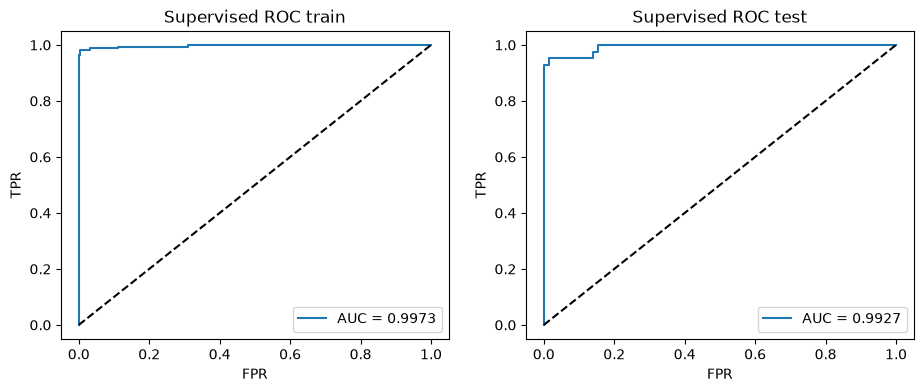

Confusion matrix train
 [[284   1]
 [  3 167]]
Confusion matrix test
 [[69  3]
 [ 2 40]]


,Accuracy,Precision,Recall,F1,AUC
Supervised train,0.987033,0.991631,0.973529,0.982479,0.997487
Supervised test,0.966082,0.971280,0.936508,0.953082,0.992593


In [8]:
#b i supervised learning , 30 runs and each time 20% of each class goes into test (stratify takes care of that)
suptrain = []
suptest = []
for m in range(M):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, stratify=y, random_state= m)
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)   #only fitting on train otherwise its data leakage
    grid = GridSearchCV(LinearSVC(penalty="l1", dual=False, max_iter=10000), {"C": Cs}, cv=5)
    grid.fit(X_train, y_train)
    svm = grid.best_estimator_
    predtr = svm.predict(X_train)
    predte = svm.predict(X_test)
    suptrain.append(getscores(y_train, predtr, svm.decision_function(X_train)))
    suptest.append(getscores(y_test, predte, svm.decision_function(X_test)))
    if m == 0:
        print("best C for run 0:", grid.best_params_["C"])
        plotroc_cm(y_train, predtr, svm.decision_function(X_train), y_test, predte, svm.decision_function(X_test), "Supervised")

supresults = pd.DataFrame([np.mean(suptrain, axis=0), np.mean(suptest, axis=0)], columns=cols,
                          index=["Supervised train", "Supervised test"])
supresults

best C for run 0: 0.1


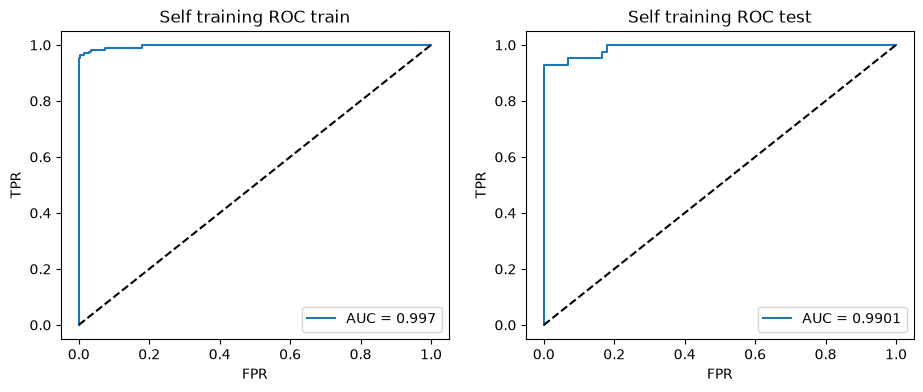

Confusion matrix train
 [[284   1]
 [  6 164]]
Confusion matrix test
 [[68  4]
 [ 3 39]]


,Accuracy,Precision,Recall,F1,AUC
Semi supervised train,0.977143,0.979326,0.959412,0.969089,0.994369
Semi supervised test,0.962281,0.964991,0.932540,0.947891,0.991369


In [9]:
#b ii semi supervised / self training
#in each run 50% of each class in the train set is labeled and rest is unlabeled
semitrain = []
semitest = []
for m in range(M):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, stratify=y, random_state= m)
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    #splitting train again into labeled half and unlabeled half
    XL, XU, yL, yU = train_test_split(X_train, y_train, test_size=0.5, stratify=y_train, random_state= m)
    #A. training L1 svm on labeled data only with cv for C
    grid = GridSearchCV(LinearSVC(penalty="l1", dual=False, max_iter=10000), {"C": Cs}, cv=5)
    grid.fit(XL, yL)
    bestC = grid.best_params_["C"]
    svm = grid.best_estimator_
    #B. find the unlabeled point farthest from the hyperplane , label it using svm and retrain , repeat till nothing is left
    while len(XU) > 0:
        dist = np.abs(svm.decision_function(XU))  #not dividing by ||w|| since its same for every point
        far = np.argmax(dist)
        XL = np.vstack([XL, XU[far]])
        yL = np.append(yL, svm.predict(XU[far].reshape(1, -1)))
        XU = np.delete(XU, far, axis=0)
        svm = LinearSVC(penalty="l1", dual=False, C=bestC, max_iter=10000).fit(XL, yL)
    predtr = svm.predict(X_train)
    predte = svm.predict(X_test)
    semitrain.append(getscores(y_train, predtr, svm.decision_function(X_train)))
    semitest.append(getscores(y_test, predte, svm.decision_function(X_test)))
    if m == 0:
        print("best C for run 0:", bestC)
        plotroc_cm(y_train, predtr, svm.decision_function(X_train), y_test, predte, svm.decision_function(X_test), "Self training")

semiresults = pd.DataFrame([np.mean(semitrain, axis=0), np.mean(semitest, axis=0)], columns=cols,
                           index=["Semi supervised train", "Semi supervised test"])
semiresults

In [10]:
#b iii A. kmeans can get stuck in a local minima depending on where the centers start
#so checking inertia for different random starts, n_init runs it many times and keeps the lowest inertia one
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, stratify=y, random_state= 0)
X_train = StandardScaler().fit_transform(X_train)
inertias = []
for s in range(10):
    km = KMeans(n_clusters=2, init="random", n_init=1, random_state=s).fit(X_train)
    inertias.append(round(km.inertia_, 2))
print(inertias)

[9216.68, 9216.68, 9216.68, 9216.68, 9216.68, 9216.68, 9216.68, 9216.68, 9216.68, 9216.68]


cluster labels run 0: [0 1]


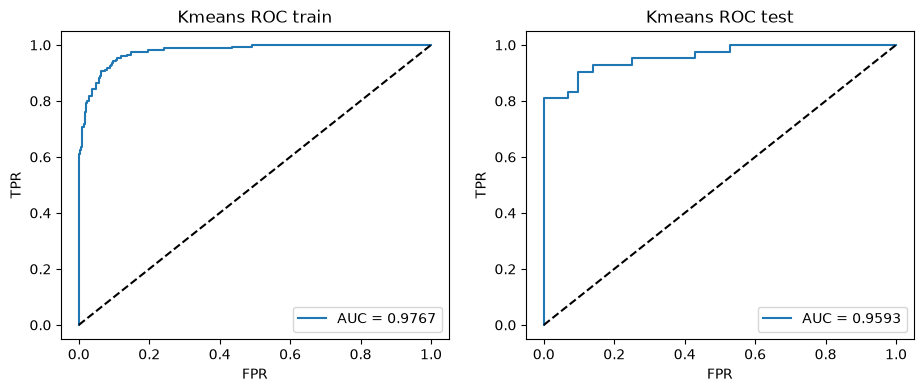

Confusion matrix train
 [[277   8]
 [ 33 137]]
Confusion matrix test
 [[65  7]
 [ 7 35]]


,Accuracy,Precision,Recall,F1,AUC
Kmeans train,0.910256,0.923690,0.828627,0.873381,0.974841
Kmeans test,0.905556,0.909718,0.826984,0.865157,0.971836


In [11]:
#b iii kmeans with k =2 as a classifier
kmtrain = []
kmtest = []
for m in range(M):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, stratify=y, random_state= m)
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    km = KMeans(n_clusters=2, init="random", n_init=10, random_state= m).fit(X_train)
    disttr = km.transform(X_train)   #distance of every point from both the centers
    distte = km.transform(X_test)
    #B. label of each cluster = majority of true labels of the 30 points closest to that center
    clusterlabel = np.zeros(2, dtype=int)
    for c in range(2):
        closest = np.argsort(disttr[:, c])[:30]
        clusterlabel[c] = np.bincount(y_train[closest]).argmax()
    #C. test points just go to the nearest center
    predtr = clusterlabel[km.predict(X_train)]
    predte = clusterlabel[km.predict(X_test)]
    #for roc we need a score, using softmax of negative distances so closer to malignant center = higher score
    probtr = np.exp(-disttr) / np.exp(-disttr).sum(axis=1, keepdims=True)
    probte = np.exp(-distte) / np.exp(-distte).sum(axis=1, keepdims=True)
    scoretr = probtr[:, clusterlabel == 1].sum(axis=1)
    scorete = probte[:, clusterlabel == 1].sum(axis=1)
    kmtrain.append(getscores(y_train, predtr, scoretr))
    kmtest.append(getscores(y_test, predte, scorete))
    if m == 0:
        print("cluster labels run 0:", clusterlabel)
        plotroc_cm(y_train, predtr, scoretr, y_test, predte, scorete, "Kmeans")

kmresults = pd.DataFrame([np.mean(kmtrain, axis=0), np.mean(kmtest, axis=0)], columns=cols,
                         index=["Kmeans train", "Kmeans test"])
kmresults

In [12]:
#b iv spectral clustering, first trying different gamma because gamma =1 puts almost everything into one cluster
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, stratify=y, random_state= 0)
X_train = StandardScaler().fit_transform(X_train)
for g in [1, 0.1, 0.01, 0.005, 0.001]:
    lab = SpectralClustering(n_clusters=2, affinity="rbf", gamma=g, random_state=0).fit_predict(X_train)
    print(g, "cluster sizes:", np.bincount(lab))

1 cluster sizes: [453   2]


0.1 cluster sizes: [453   2]
0.01 cluster sizes: [119 336]


0.005 cluster sizes: [321 134]
0.001 cluster sizes: [145 310]


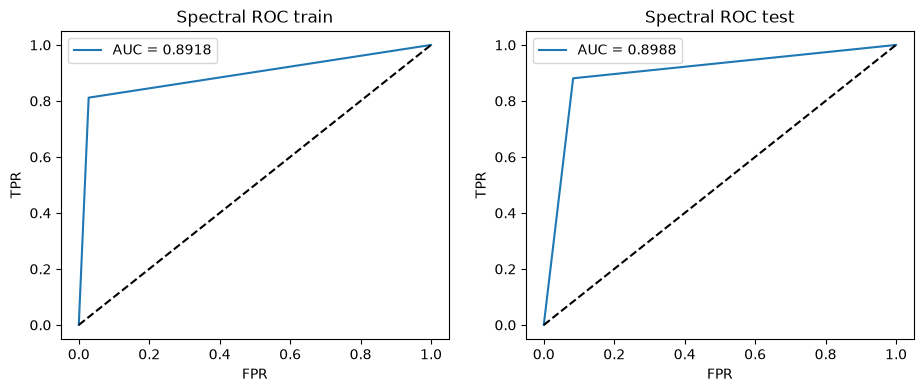

Confusion matrix train
 [[277   8]
 [ 32 138]]
Confusion matrix test
 [[66  6]
 [ 5 37]]


,Accuracy,Precision,Recall,F1,AUC
Spectral train,0.91011,0.929139,0.822353,0.872344,0.892405
Spectral test,0.90731,0.919477,0.822222,0.866783,0.889583


In [13]:
#gamma = 0.001 gives sizes close to the actual 357/212 split so going with that
#spectral clustering has no predict so i am clustering train and test together (no labels used so its fine)
sptrain = []
sptest = []
for m in range(M):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, stratify=y, random_state= m)
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    Xall = np.vstack([X_train, X_test])
    labels = SpectralClustering(n_clusters=2, affinity="rbf", gamma=0.001, random_state= m).fit_predict(Xall)
    labtr = labels[:len(X_train)]
    labte = labels[len(X_train):]
    #majority polling with 30 random train points from each cluster
    rng = np.random.RandomState(m)
    fracM = np.zeros(2)
    for c in range(2):
        members = np.where(labtr == c)[0]
        pick = rng.choice(members, size=min(30, len(members)), replace=False)
        fracM[c] = y_train[pick].mean()   #fraction of malignant in the poll
    clusterlabel = (fracM > 0.5).astype(int)
    predtr = clusterlabel[labtr]
    predte = clusterlabel[labte]
    #score for roc = fraction of malignant in the poll of that cluster
    sptrain.append(getscores(y_train, predtr, fracM[labtr]))
    sptest.append(getscores(y_test, predte, fracM[labte]))
    if m == 0:
        plotroc_cm(y_train, predtr, fracM[labtr], y_test, predte, fracM[labte], "Spectral")

spresults = pd.DataFrame([np.mean(sptrain, axis=0), np.mean(sptest, axis=0)], columns=cols,
                         index=["Spectral train", "Spectral test"])
spresults

In [14]:
#b v putting all of them side by side
allresults = pd.concat([supresults, semiresults, kmresults, spresults])
allresults.round(4)

,Accuracy,Precision,Recall,F1,AUC
Supervised train,0.9870,0.9916,0.9735,0.9825,0.9975
Supervised test,0.9661,0.9713,0.9365,0.9531,0.9926
Semi supervised train,0.9771,0.9793,0.9594,0.9691,0.9944
Semi supervised test,0.9623,0.9650,0.9325,0.9479,0.9914
Kmeans train,0.9103,0.9237,0.8286,0.8734,0.9748
Kmeans test,0.9056,0.9097,0.8270,0.8652,0.9718
Spectral train,0.9101,0.9291,0.8224,0.8723,0.8924
Spectral test,0.9073,0.9195,0.8222,0.8668,0.8896


Problem 2 Active learning with banknote authentication

In [15]:
bank=pd.read_csv(r"F:\USC_EE\Sem_3\DSCI_552\Hw8\data_banknote_authentication.txt", header=None)
print(bank.shape)
bank.head()

(1372, 5)


,0,1,2,3,4
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [16]:
#first 4 columns are features and the 5th is the class
Xb= bank.iloc[:, :4].values
yb= bank[4].values
#472 test points , rest 900 for training
Xb_train, Xb_test, yb_train, yb_test = train_test_split(Xb, yb, test_size= 472, random_state= 552)
scalerb = StandardScaler()
Xb_train = scalerb.fit_transform(Xb_train)
Xb_test = scalerb.transform(Xb_test)
print(Xb_train.shape, Xb_test.shape)

(900, 4) (472, 4)


In [17]:
#for small pools 5 fold cv breaks if a class has less than 5 points so reducing the folds in that case
def trainsvm(Xp, yp):
    k = min(5, np.bincount(yp, minlength=2).min())
    if k < 2:
        return LinearSVC(penalty="l1", dual=False, C=1, max_iter=10000).fit(Xp, yp)
    grid = GridSearchCV(LinearSVC(penalty="l1", dual=False, max_iter=10000), {"C": Cs},
                        cv=StratifiedKFold(k, shuffle=True, random_state=0))
    grid.fit(Xp, yp)
    return grid.best_estimator_

#first pool of 10 has to have both classes in it otherwise svm cant train
def firstpool(rng):
    while True:
        idx = rng.choice(900, 10, replace=False)
        if len(np.unique(yb_train[idx])) == 2:
            return list(idx)

In [18]:
#b i passive learning and b ii active learning, 50 times each , 90 svms per run
R = 50
passiveerr = np.zeros((R, 90))
activeerr = np.zeros((R, 90))
for r in range(R):
    rng = np.random.RandomState(r)
    #passive , just adding 10 random points every time
    pool = firstpool(rng)
    rest = [i for i in range(900) if i not in pool]
    rng.shuffle(rest)
    for step in range(90):
        svm = trainsvm(Xb_train[pool], yb_train[pool])
        passiveerr[r, step] = 1 - svm.score(Xb_test, yb_test)
        pool = pool + rest[:10]
        rest = rest[10:]
    #active , adding the 10 points that are closest to the hyperplane
    pool = firstpool(rng)
    rest = np.array([i for i in range(900) if i not in pool])
    for step in range(90):
        svm = trainsvm(Xb_train[pool], yb_train[pool])
        activeerr[r, step] = 1 - svm.score(Xb_test, yb_test)
        if len(rest) == 0:
            break
        dist = np.abs(svm.decision_function(Xb_train[rest])) / np.linalg.norm(svm.coef_)  # |w.x+b| / ||w||
        closest = np.argsort(dist)[:10]
        pool = pool + list(rest[closest])
        rest = np.delete(rest, closest)
    print("run", r, "done")

run 0 done


run 1 done


run 2 done


run 3 done


run 4 done


run 5 done


... (40 outputs left out)

run 46 done


run 47 done


run 48 done


run 49 done


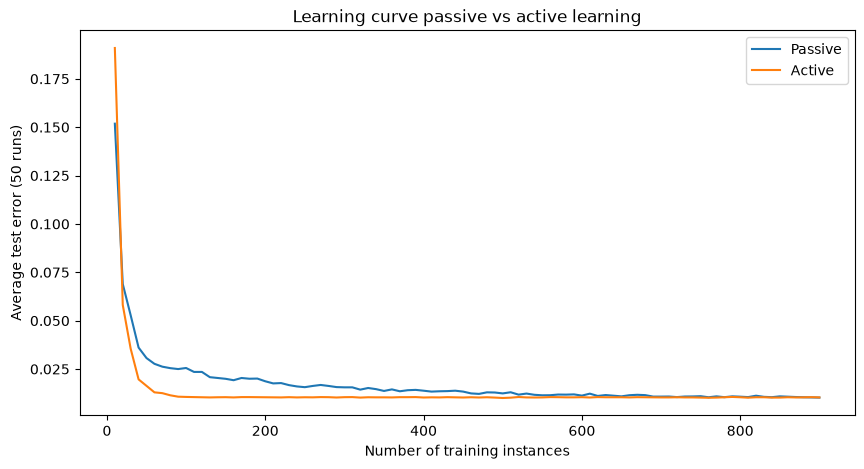

,passive,active
10,0.151822,0.190932
20,0.068941,0.058136
30,0.052797,0.035508
50,0.030678,0.016314
70,0.026229,0.012542
100,0.025551,0.010593
200,0.018686,0.010424
300,0.015551,0.010466
500,0.012415,0.010042
900,0.010254,0.010339


In [19]:
#c learning curve , average test error vs number of training points for both
ntrain = np.arange(10, 901, 10)
plt.figure(figsize=(10, 5))
plt.plot(ntrain, passiveerr.mean(axis=0), label="Passive")
plt.plot(ntrain, activeerr.mean(axis=0), label="Active")
plt.xlabel("Number of training instances")
plt.ylabel("Average test error (50 runs)")
plt.title("Learning curve passive vs active learning")
plt.legend()
plt.show()

curve = pd.DataFrame({"passive": passiveerr.mean(axis=0), "active": activeerr.mean(axis=0)}, index=ntrain)
curve.iloc[[0, 1, 2, 4, 6, 9, 19, 29, 49, 89]]

Now answering all the questions that were theoritical

Problem 1

a
C range was picked by checking it first , for C = 0.0001 and 0.001 all the weights became 0 and accuracy was stuck at 0.627 which is just predicting benign for everything (357/569)
So the grid goes from 0.001 to 1000 , anything smaller is useless

b i supervised
test accuracy = 0.966 , precision = 0.971 , recall = 0.937 , F1 = 0.953 , AUC = 0.993
train is slightly higher at 0.987 but not a big gap so no major overfitting
Best C was 0.1 in run 0 , L1 kept only around 15 features out of 30 so it does some feature selection on its own

b ii semi supervised
test accuracy = 0.962 , recall = 0.933 , AUC = 0.991
This is almost the same as supervised even though it only got true labels for half of the train set
The farthest points from the hyperplane are the ones svm is most confident about so the labels it gives them are mostly correct , that is why adding them doesnt hurt much
small drop in recall though, mistakes made early get added and stay in the training set 

b iii kmeans
A. kmeans can get stuck in local minima , but here all 10 random starts gave the exact same inertia 9216.68 so it is not really a problem in this data , still used n_init =10 to be safe
test accuracy = 0.906 , recall = 0.827 , AUC = 0.972
AUC is high even though accuracy is lower which means the distance to the centers ranks the points well , the problem is the boundary between the two centers is not at the right place

b iv spectral
gamma =1 was useless it gave 453 vs 2 , so tried smaller gammas and 0.001 gave 145/310 which is closer to actual 212/357
test accuracy = 0.907 , recall = 0.822 , AUC = 0.890
Accuracy is basically same as kmeans but AUC is a lot lower because the score is only fraction of malignant in the poll so every point in one cluster gets the same score , so the roc only has like 1 or 2 steps

b v comparison
Supervised > Semi supervised > Kmeans ~= Spectral 
supervised and semi supervised are very close (0.966 vs 0.962) , so having labels for only half the data is almost enough here
Both unsupervised methods drop to around 0.906 because they dont use labels at all , they just group based on distance and the clusters dont exactly line up with B and M
for cancer the recall matters the most since missing a malignant tumor is the worst mistake , supervised has the best recall 0.937 and the clustering ones miss around 17-18% of malignant cases which is not acceptable 

Problem 2

c
Active learning is worse at the very start , at 10 points active error is 0.19 and passive is 0.15 because the first svm is bad so the points closest to its hyperplane are not that useful
but from 20 points onwards active is better every time
active reaches ~1.6% error at 50 points and ~1.1% at 70-100 points and then stays flat
passive is still at 2.6% at 100 points and 1.9% at 200 , it only comes down to ~1.2% around 500
At 900 both are the same ~1.0% which makes sense since both have the exact same full training set by then
Conclusion is that active learning needs way less labeled data to get to the same error , because points near the hyperplane are the ones that actually decide where the boundary is, random points far away from the boundary dont change the svm much